Loading PairA
PairA: 12 source organs
['AGM', 'Brain', 'Branchial arch', 'Cavity', 'Connective tissue', 'Dermomyotome', 'Heart', 'Liver', 'Mesenchyme', 'Neural crest', 'Notochord', 'Sclerotome']
Loading PairC
PairC: 18 source organs
['Blood vessel', 'Brain', 'Cavity', 'Choroid plexus', 'Connective tissue', 'Dermomyotome', 'Dorsal root ganglion', 'Head mesenchyme', 'Heart', 'Jaw and tooth', 'Liver', 'Lung primordium', 'Mesenchyme', 'Mucosal epithelium', 'Notochord', 'Sclerotome', 'Spinal cord', 'Urogenital ridge']

##############################################################################################################
PairA: plotting all 12 source organs
##############################################################################################################

=== PairA | AGM ===


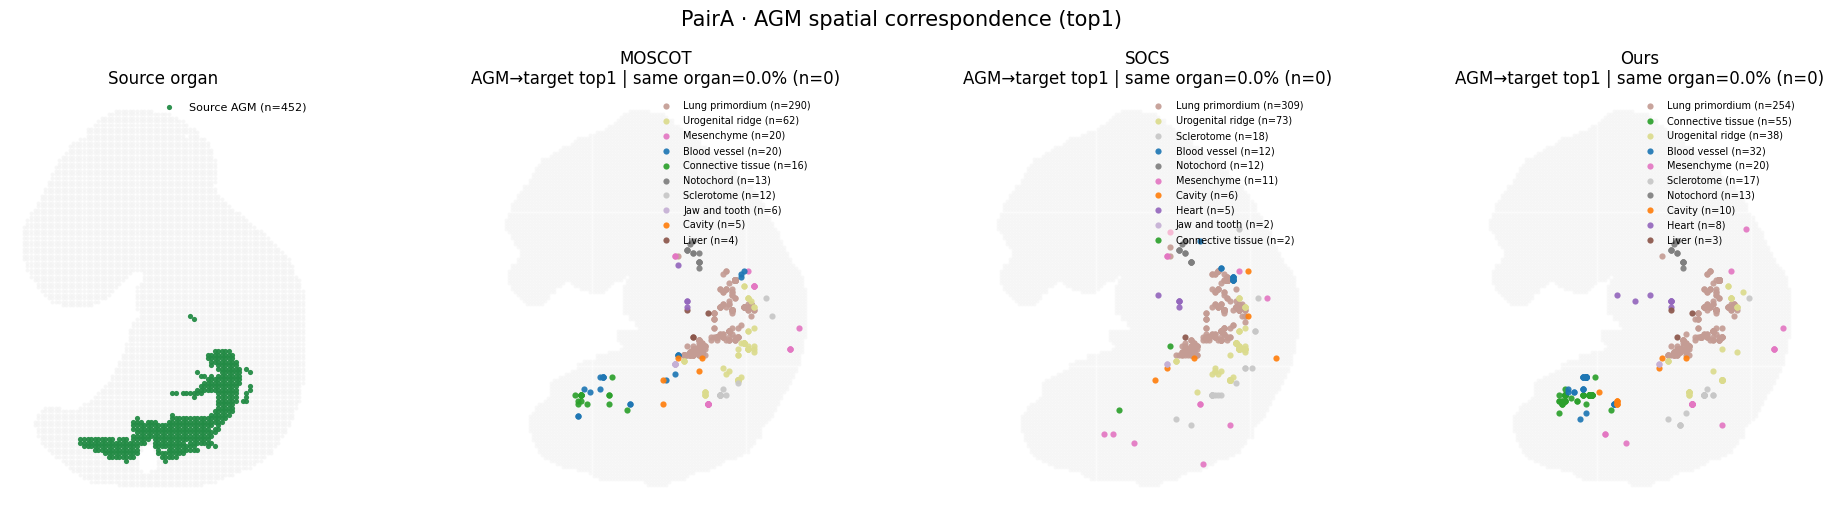


=== PairA | Brain ===


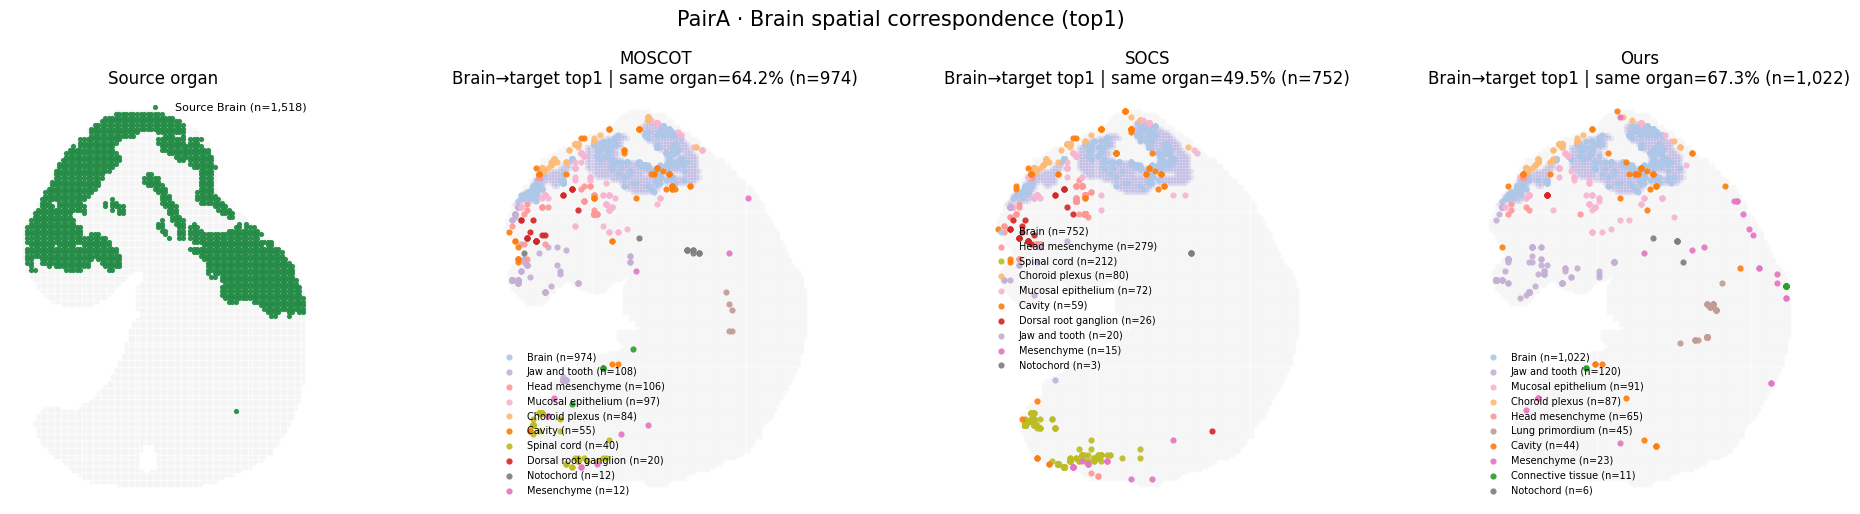


=== PairA | Branchial arch ===


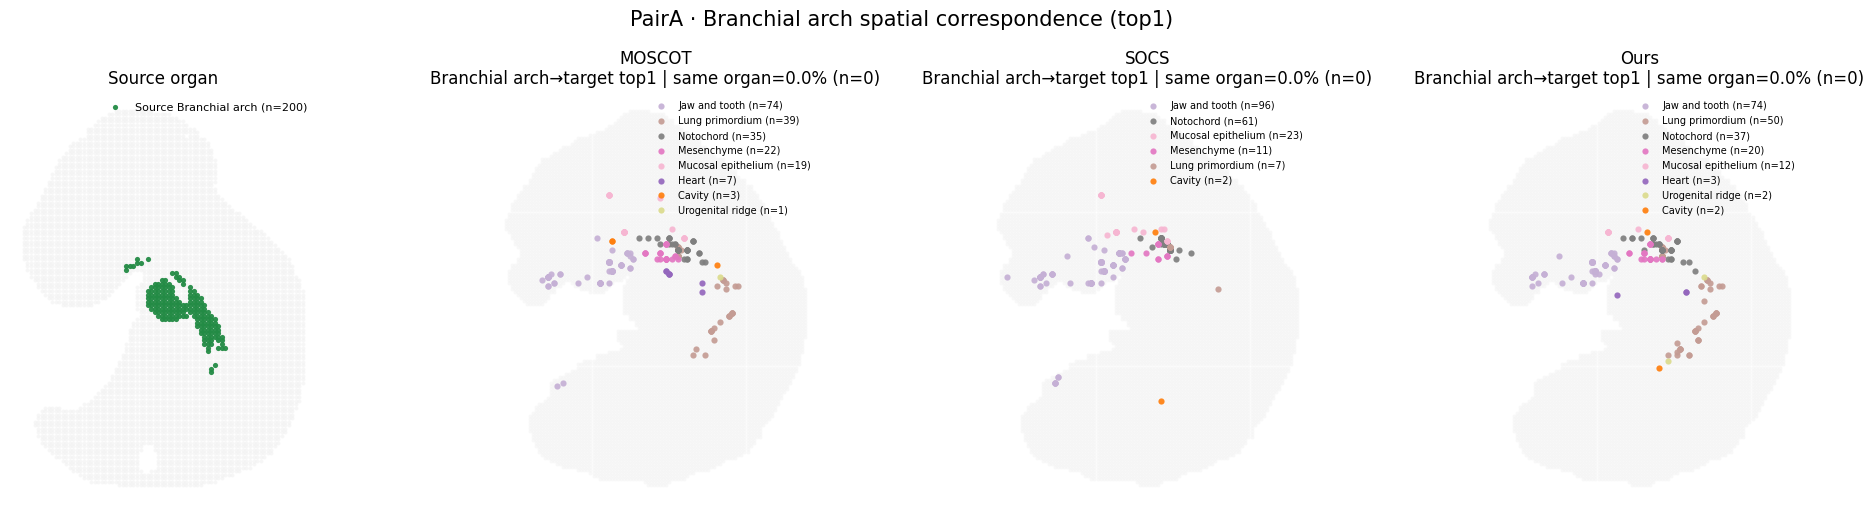


=== PairA | Cavity ===


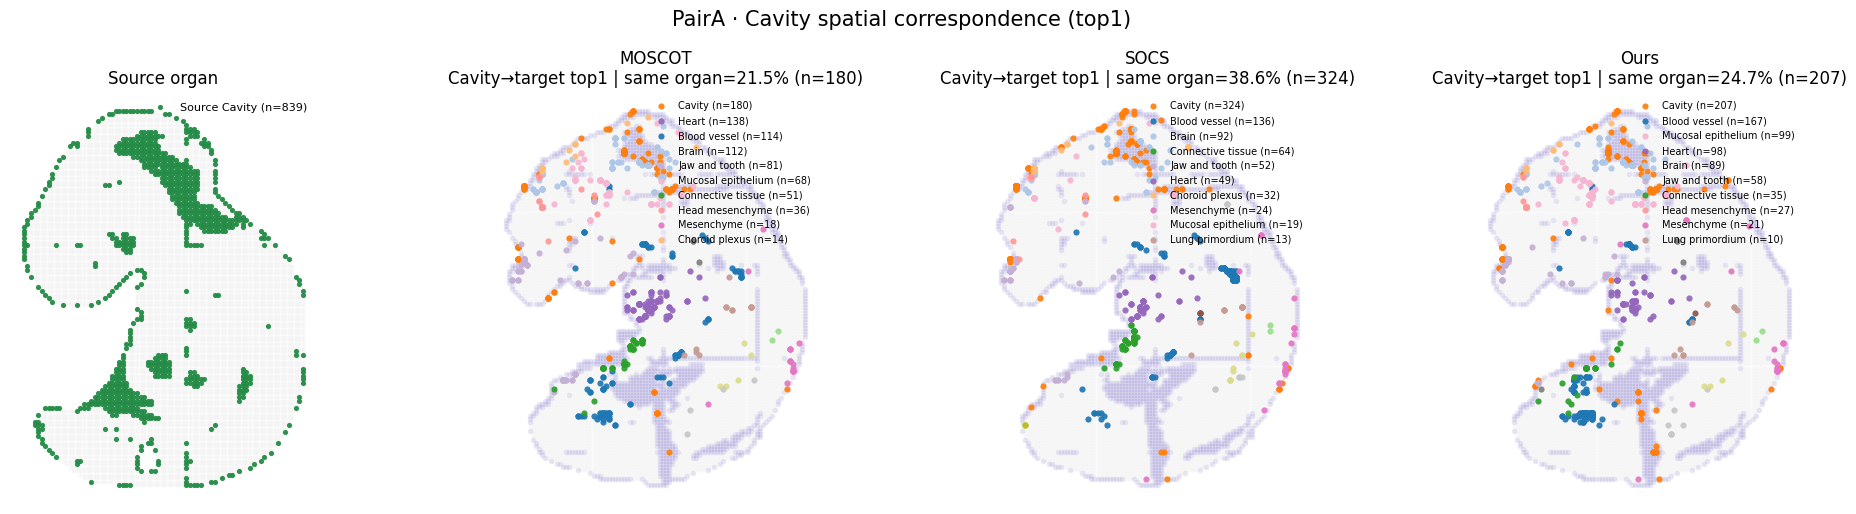


=== PairA | Connective tissue ===


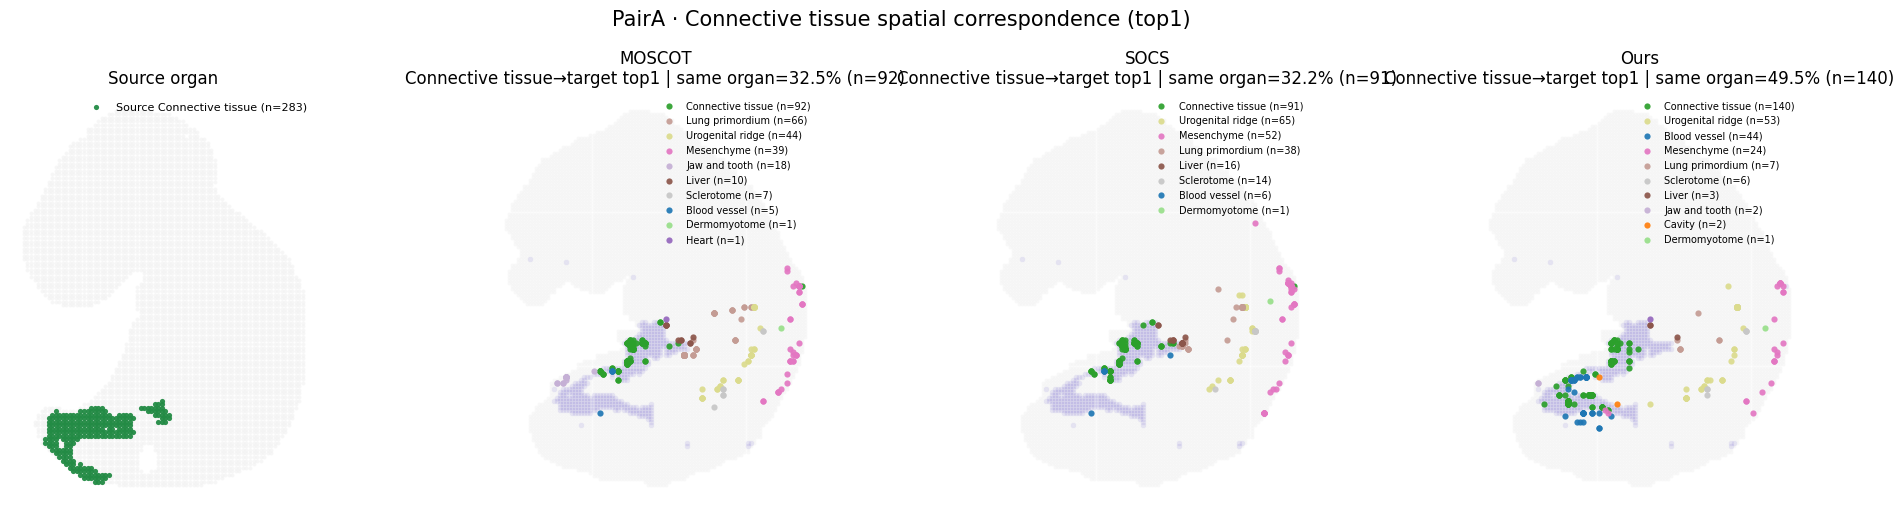


=== PairA | Dermomyotome ===


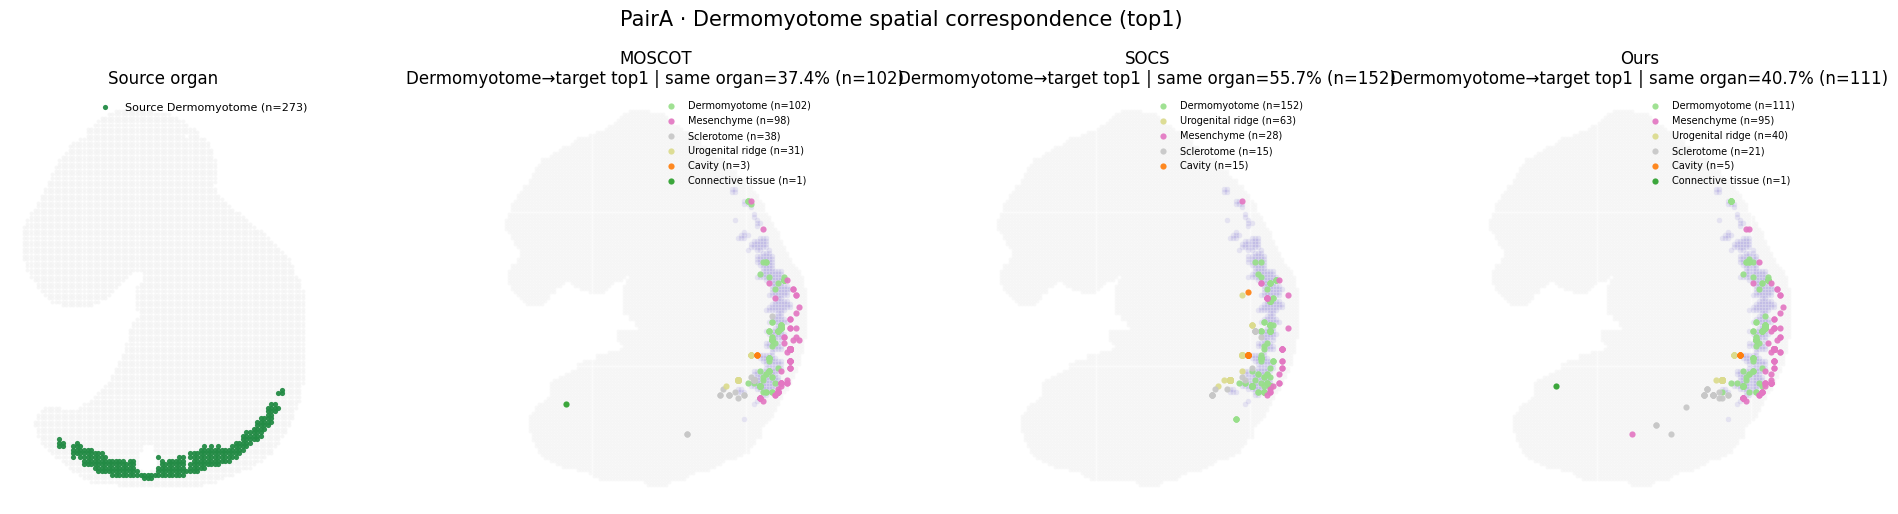


=== PairA | Heart ===


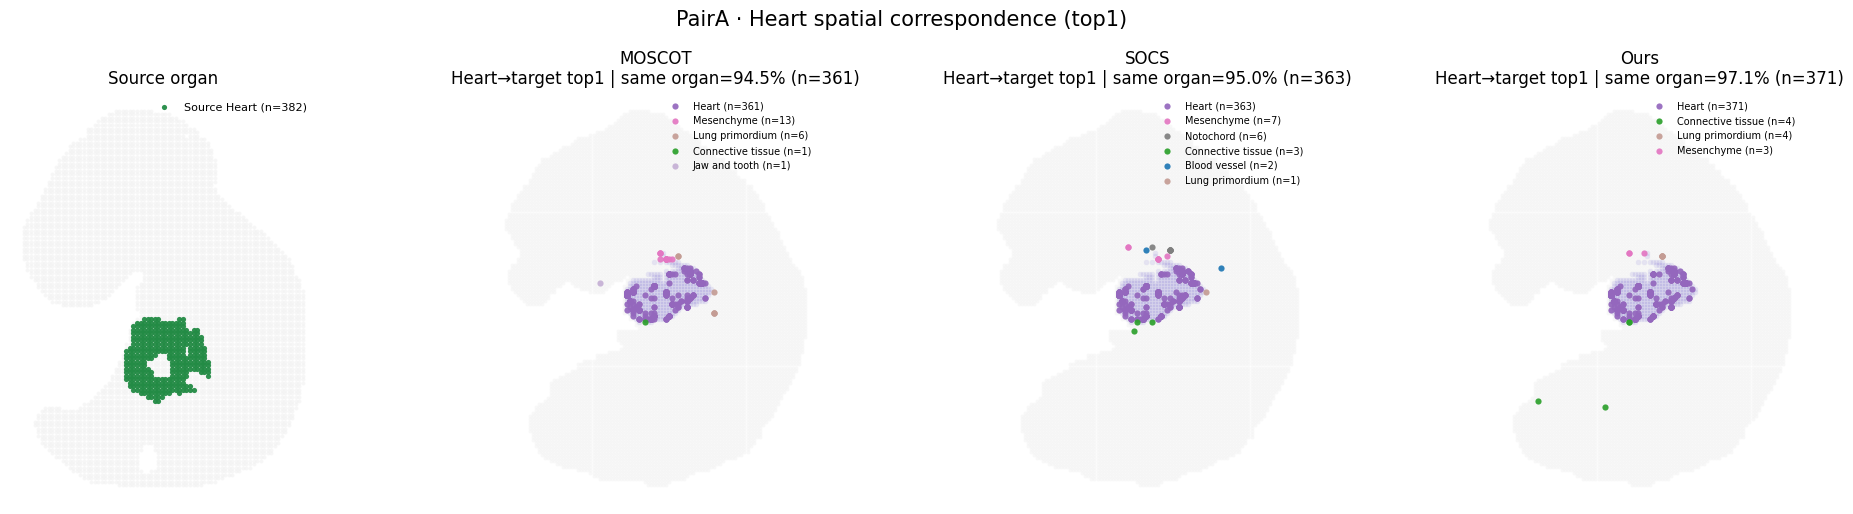


=== PairA | Liver ===


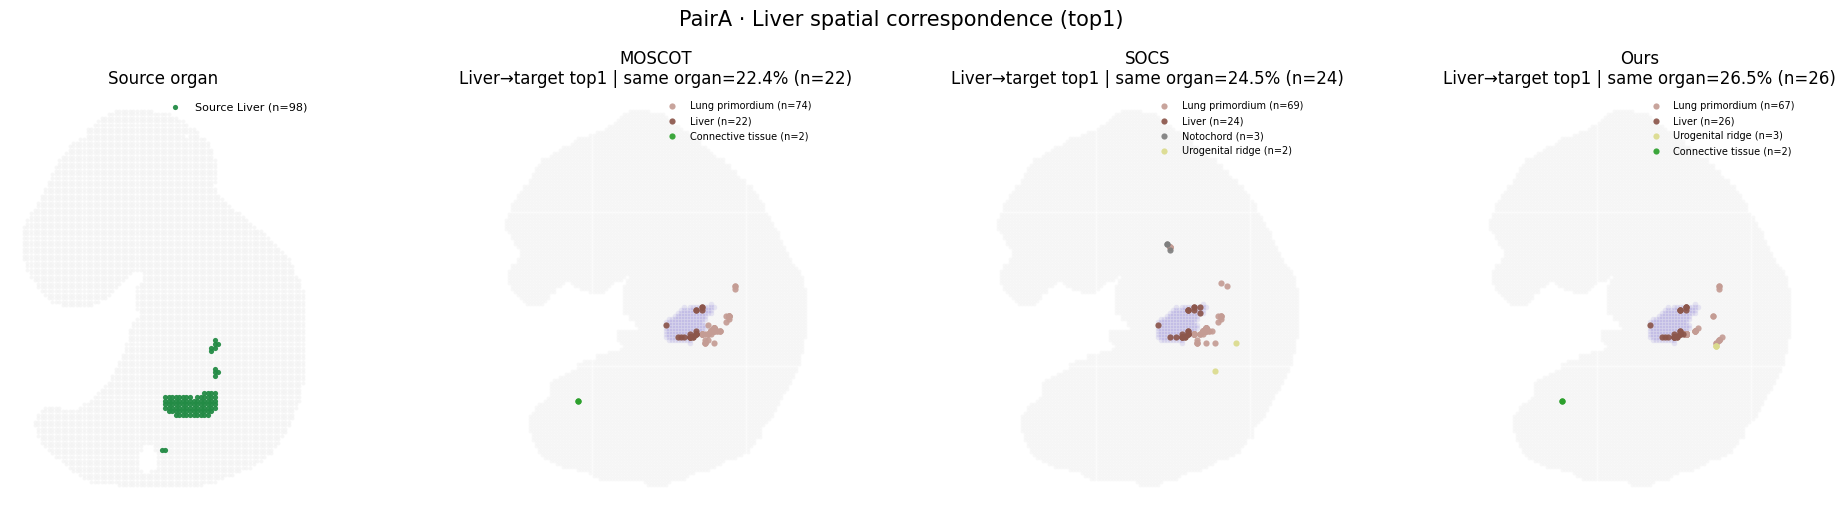


=== PairA | Mesenchyme ===


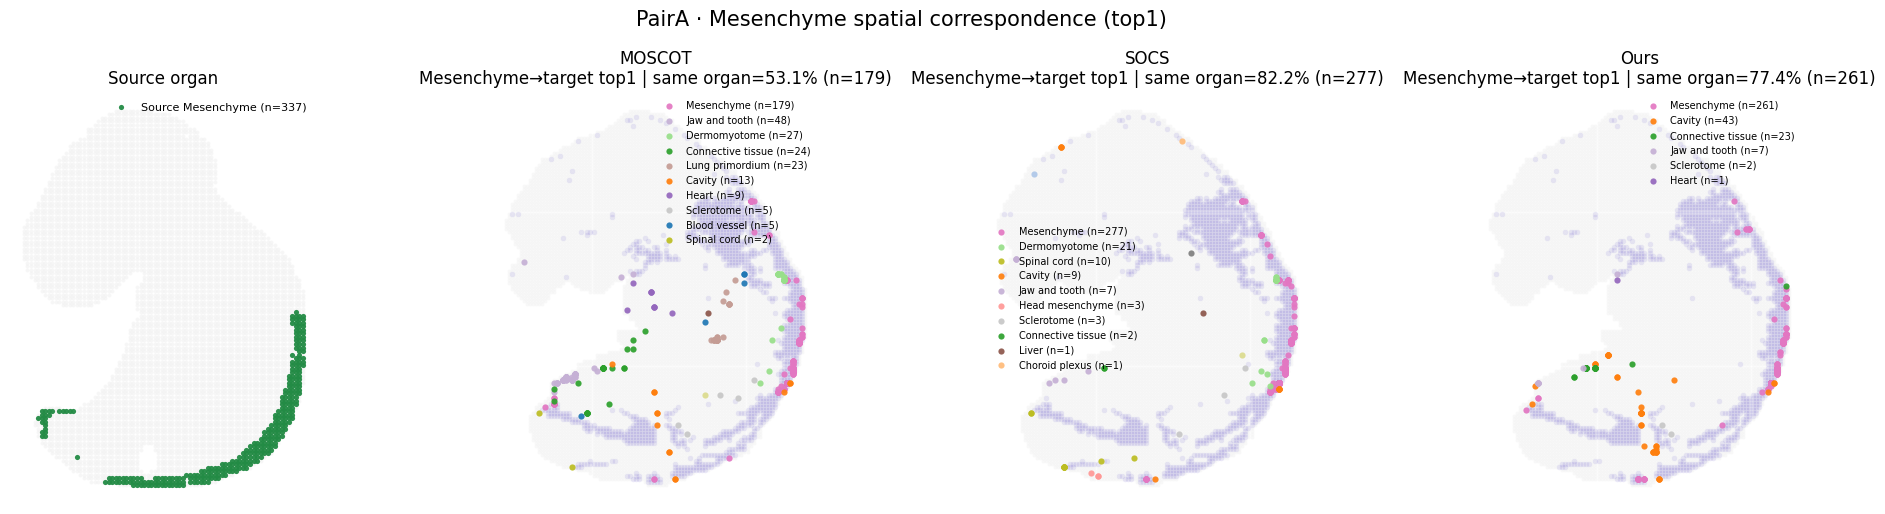


=== PairA | Neural crest ===


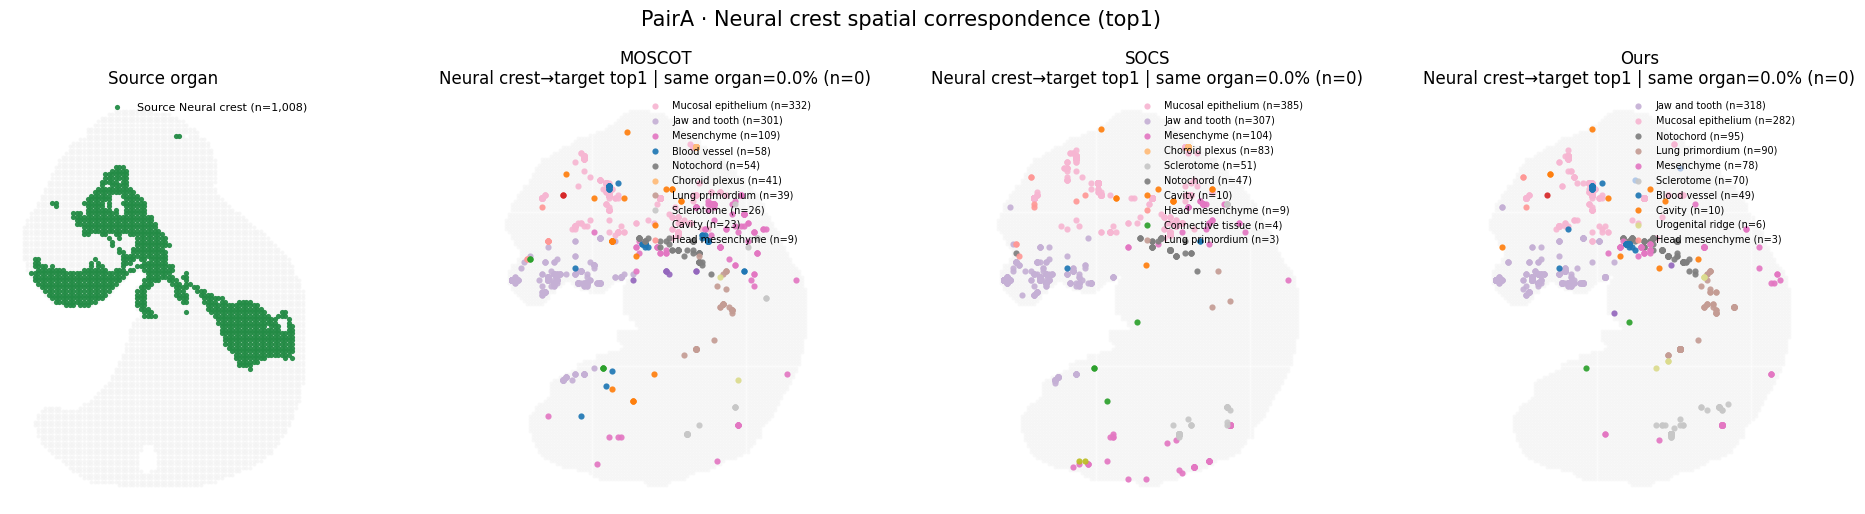


=== PairA | Notochord ===


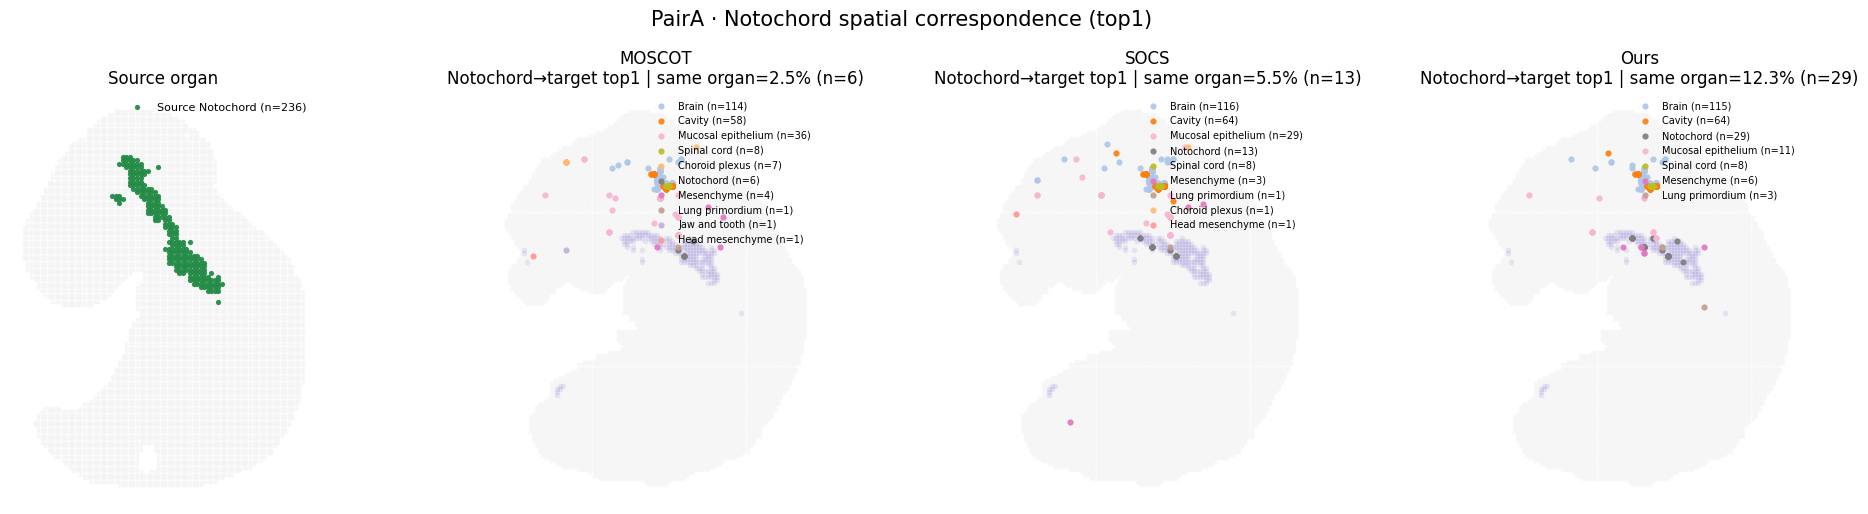


=== PairA | Sclerotome ===


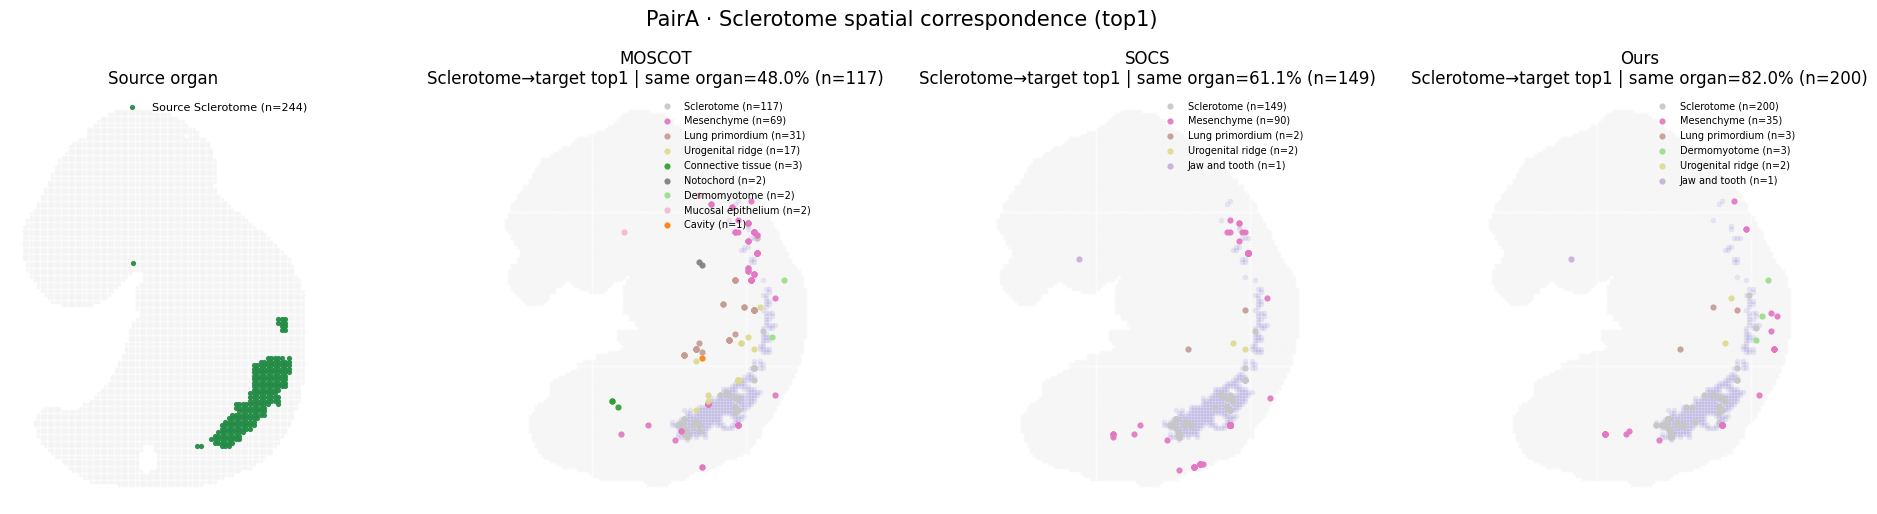


##############################################################################################################
PairC: plotting all 18 source organs
##############################################################################################################

=== PairC | Blood vessel ===


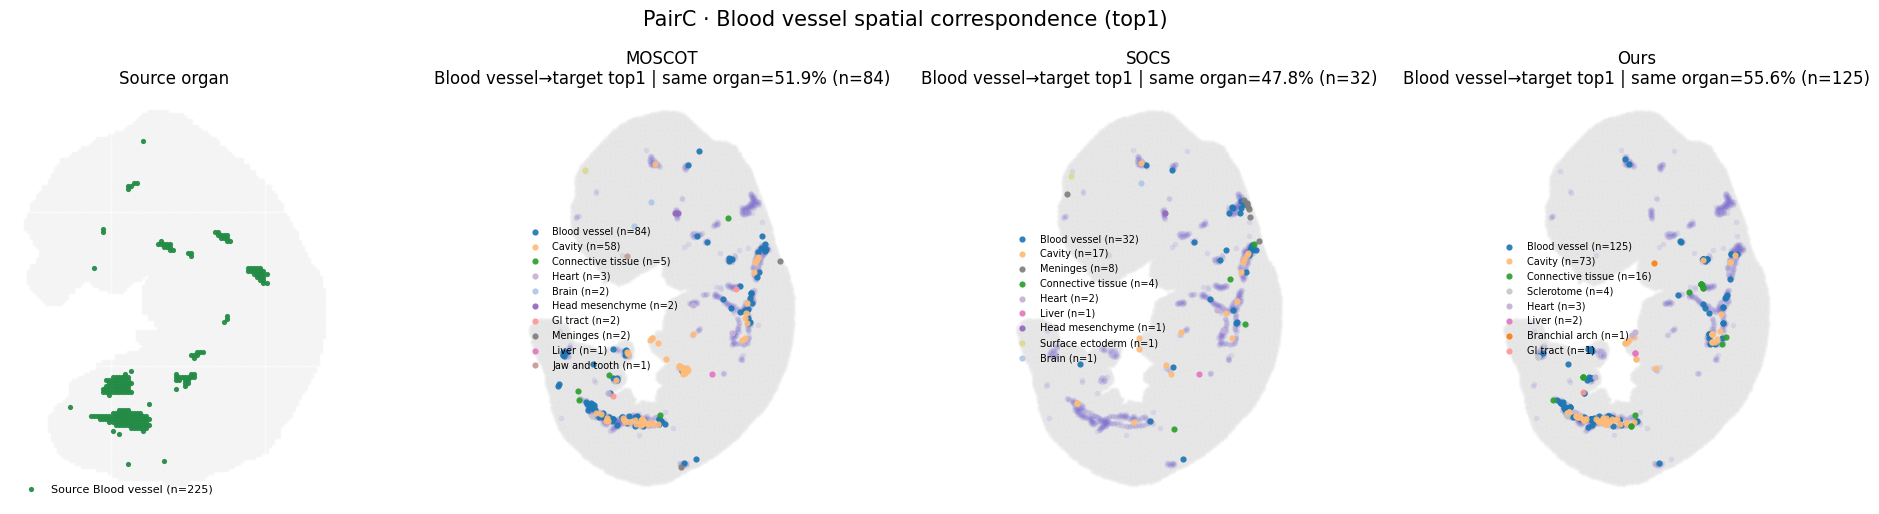


=== PairC | Brain ===


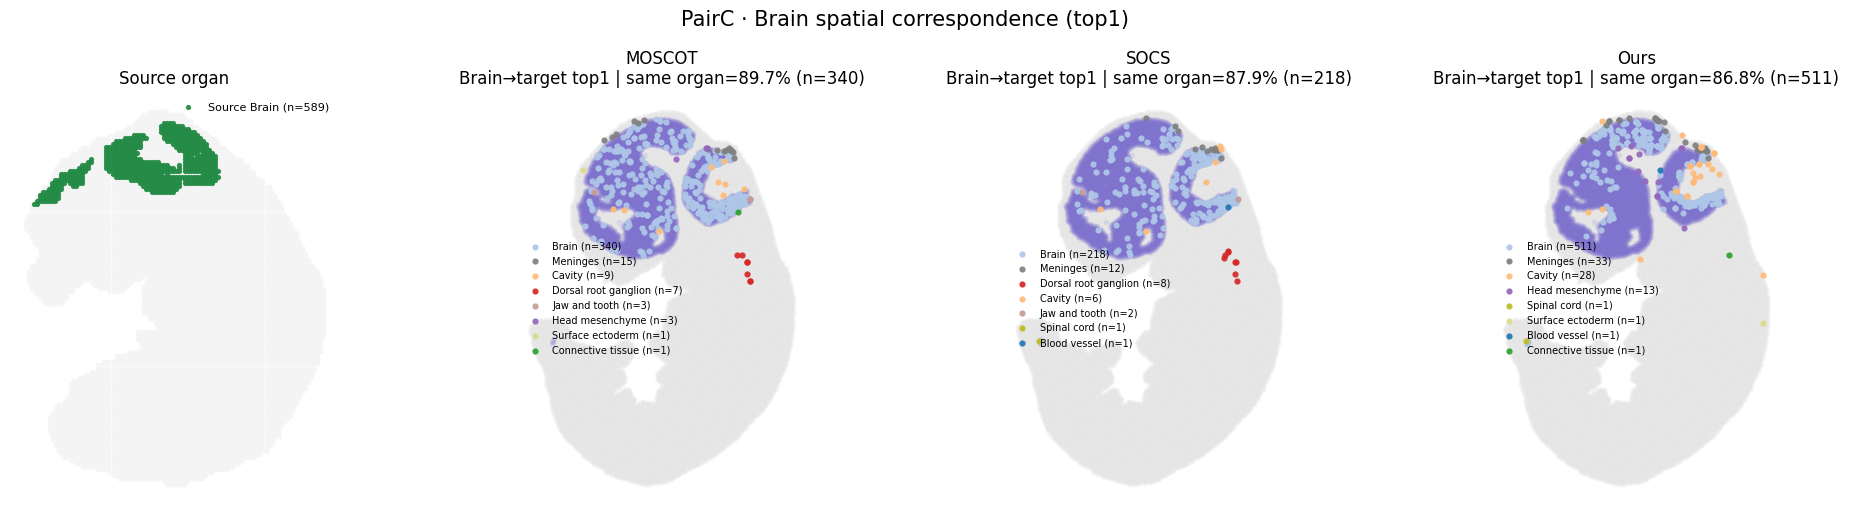


=== PairC | Cavity ===


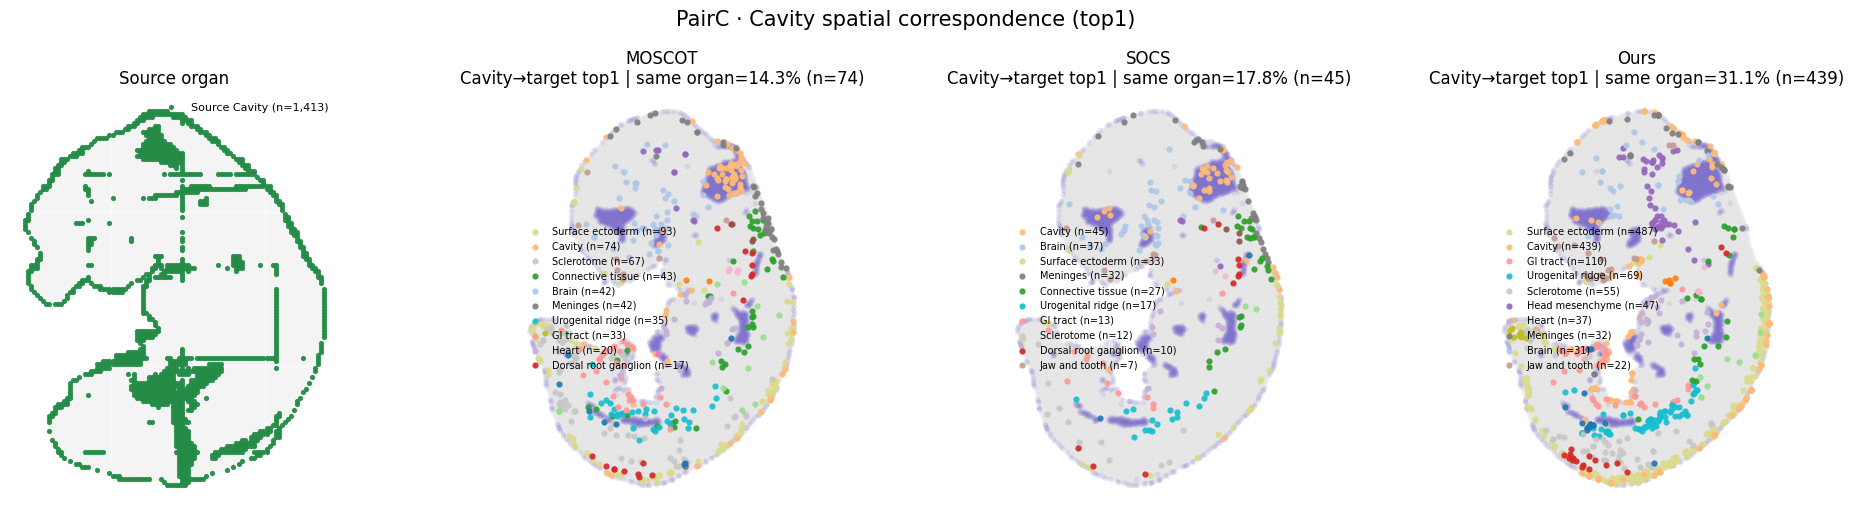


=== PairC | Choroid plexus ===


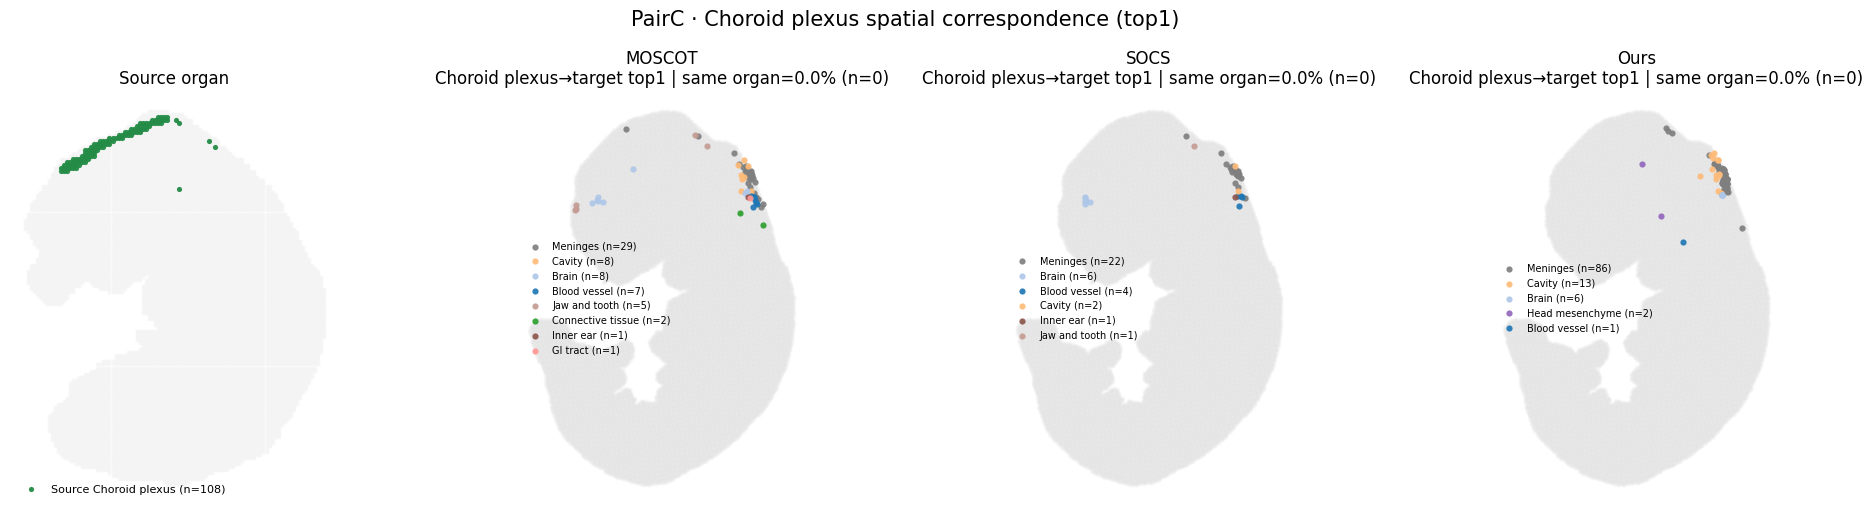


=== PairC | Connective tissue ===


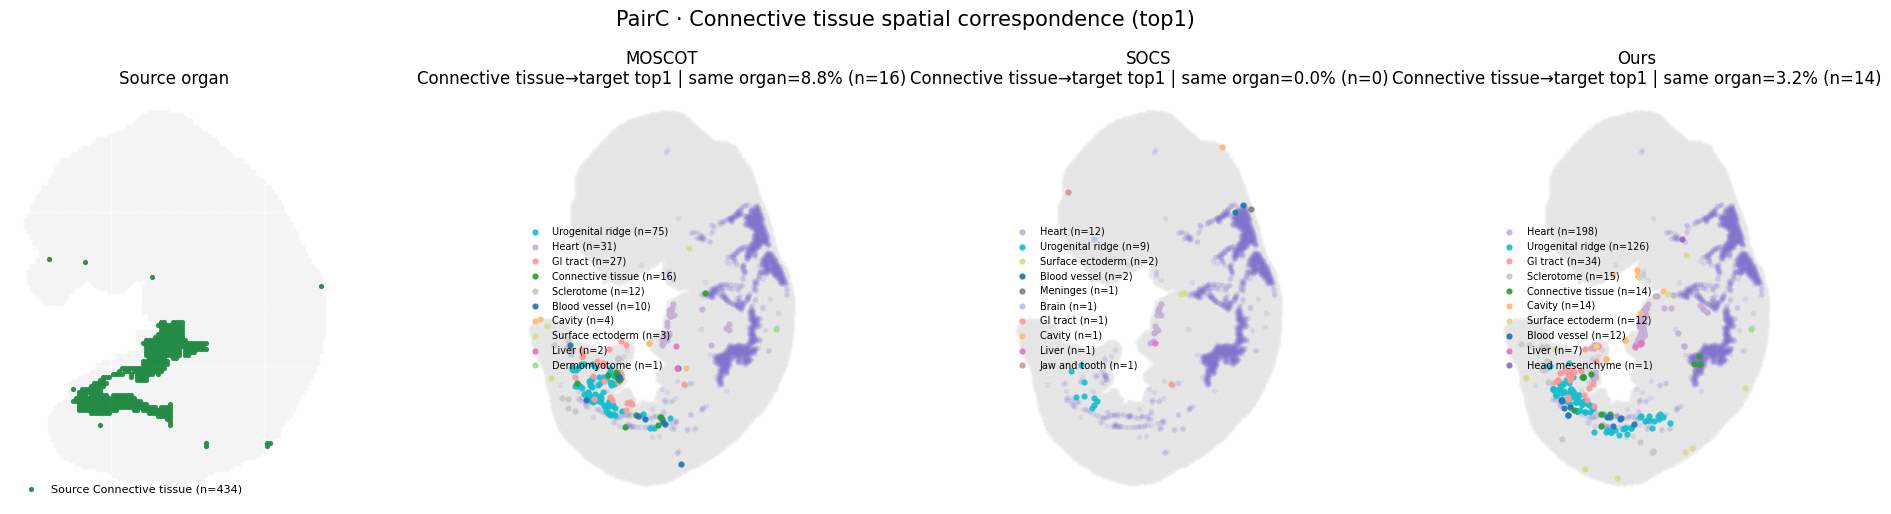


=== PairC | Dermomyotome ===


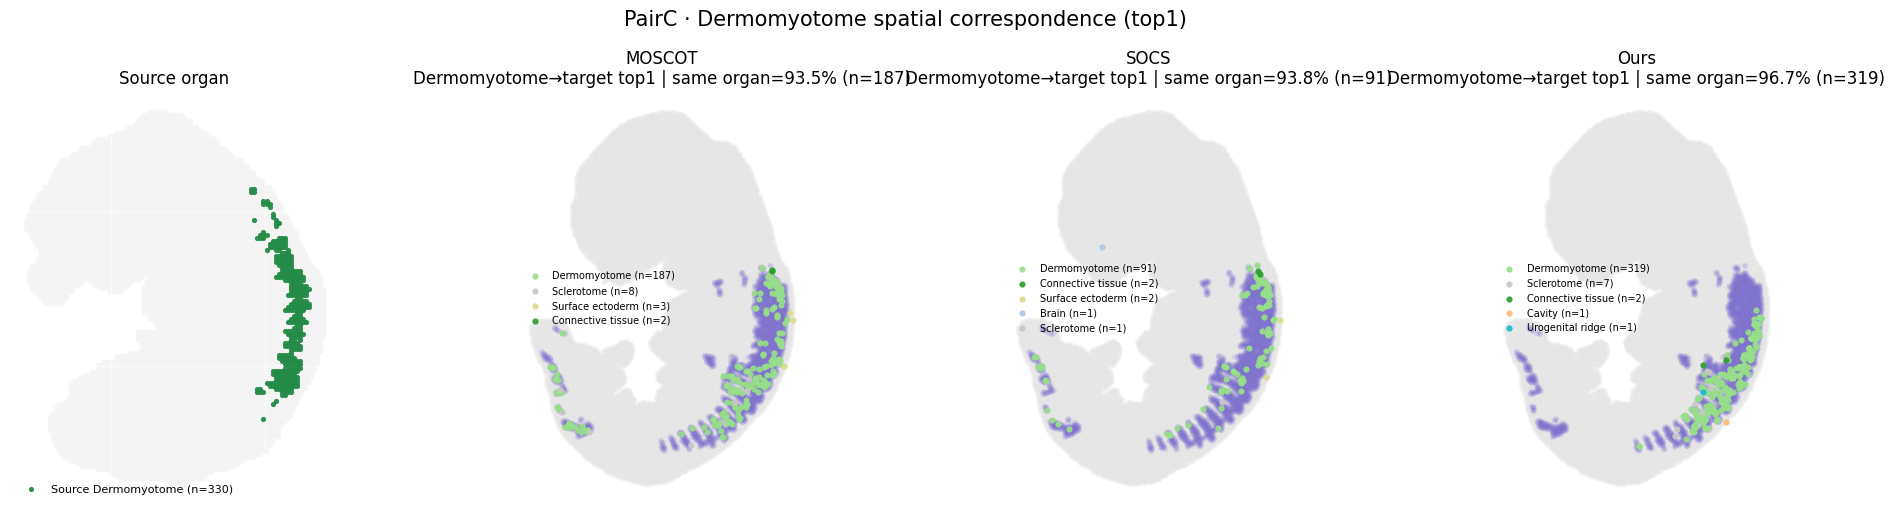


=== PairC | Dorsal root ganglion ===


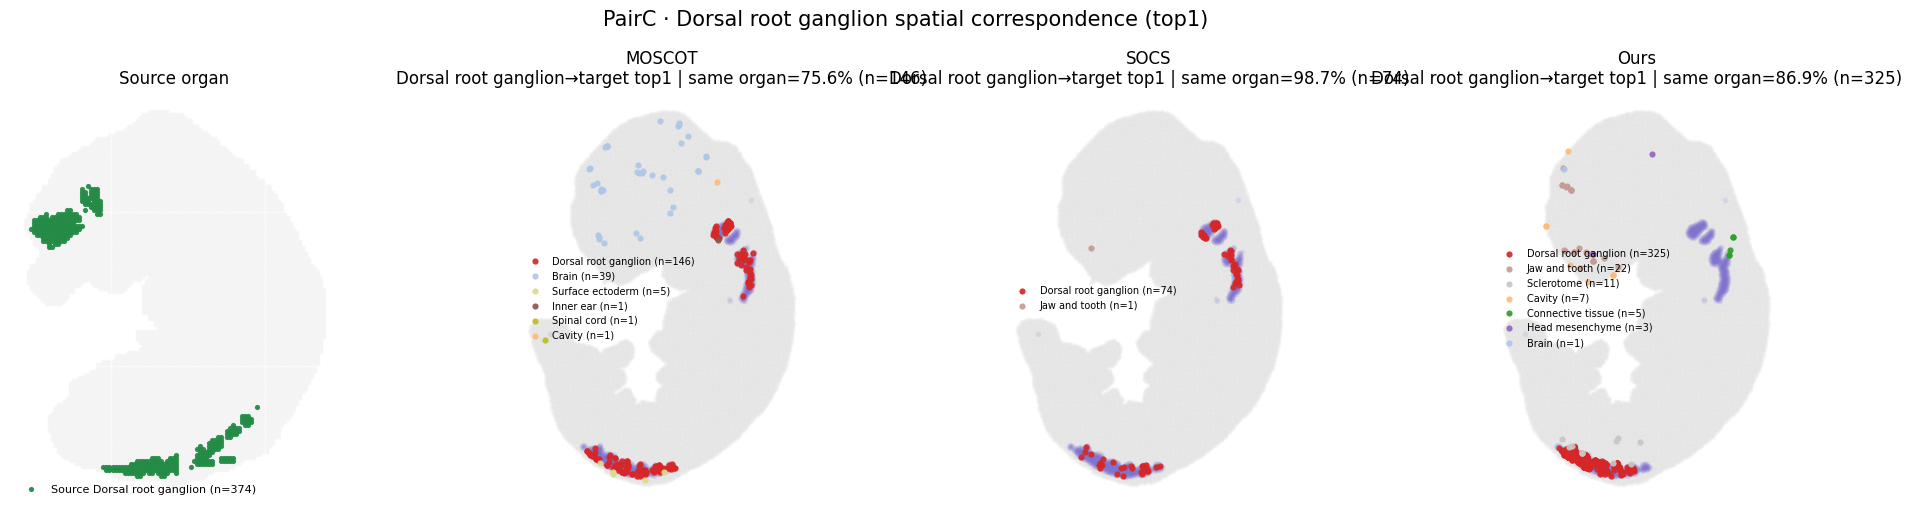


=== PairC | Head mesenchyme ===


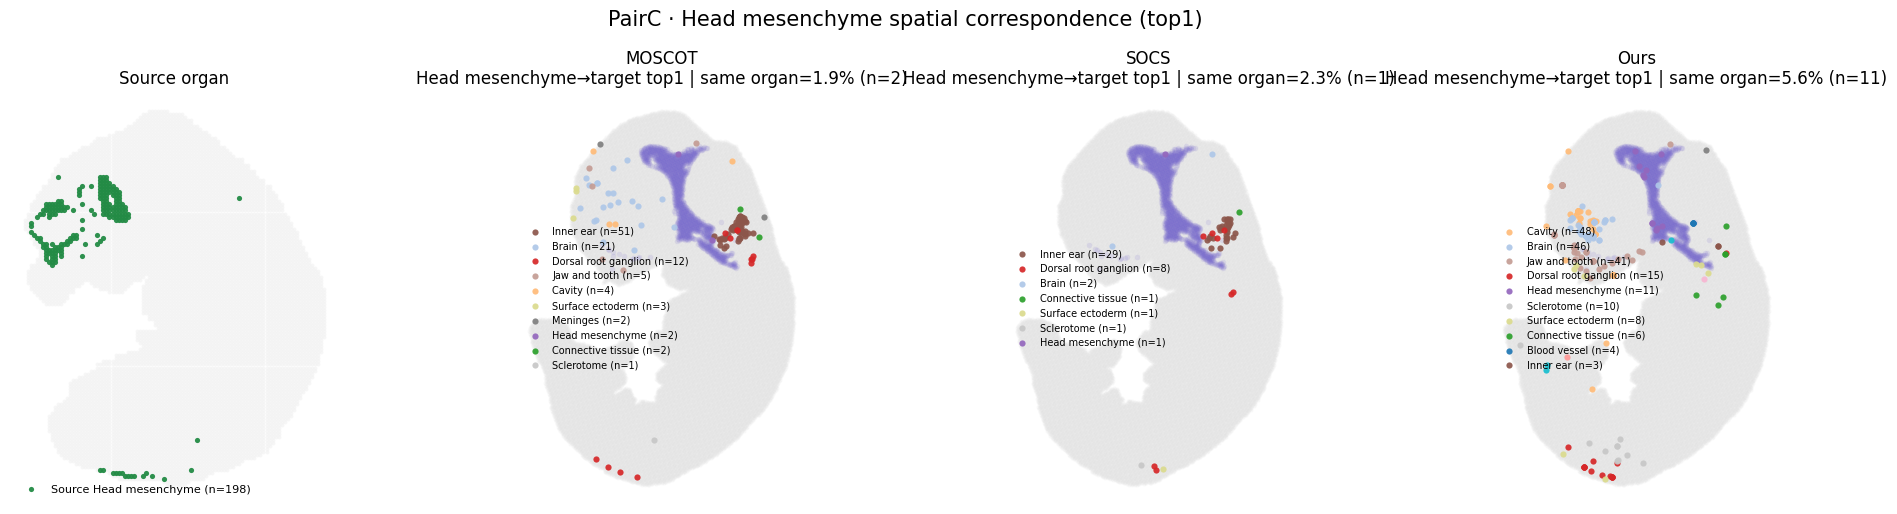


=== PairC | Heart ===


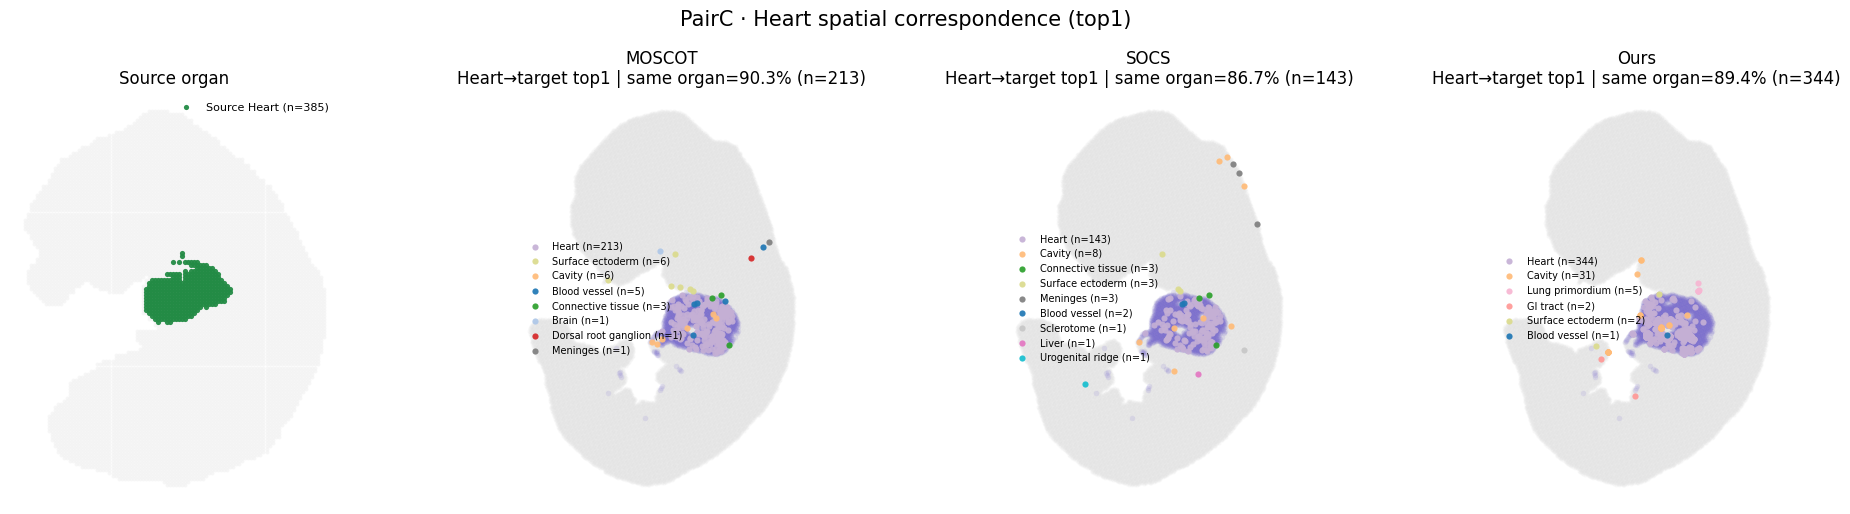


=== PairC | Jaw and tooth ===


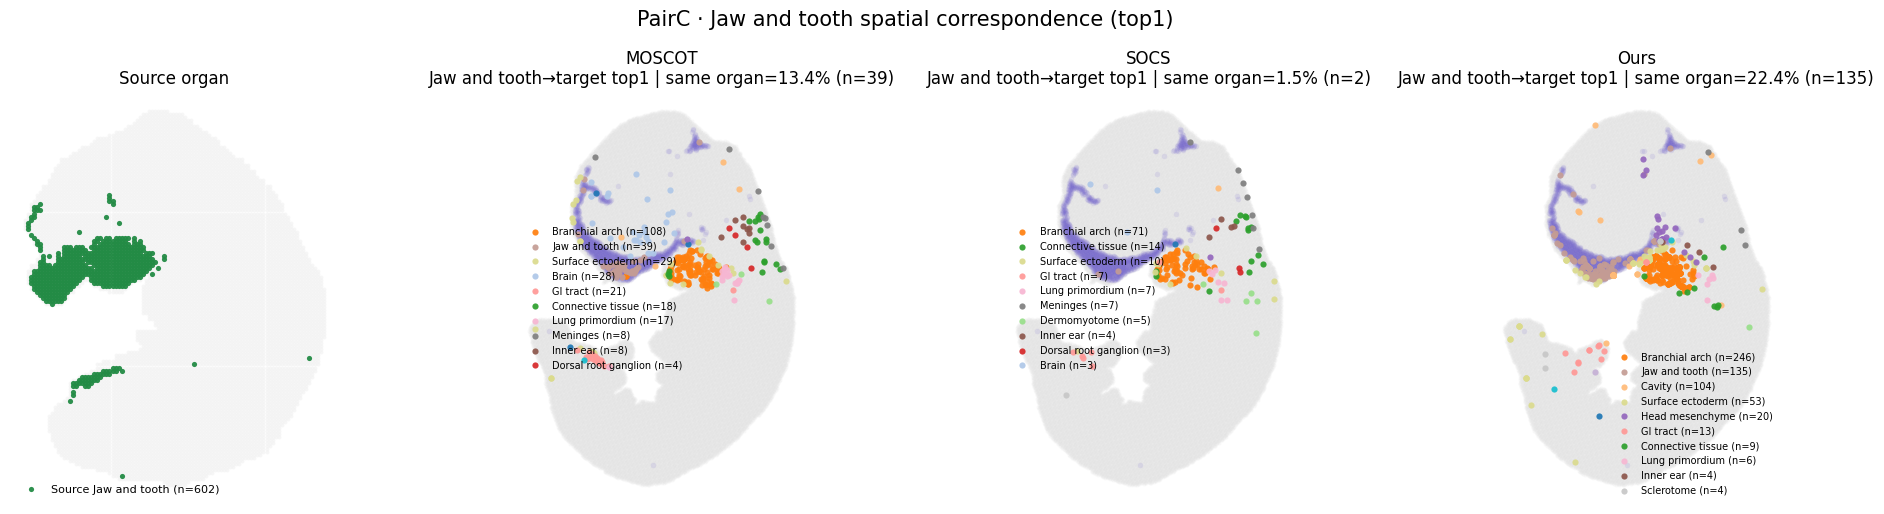


=== PairC | Liver ===


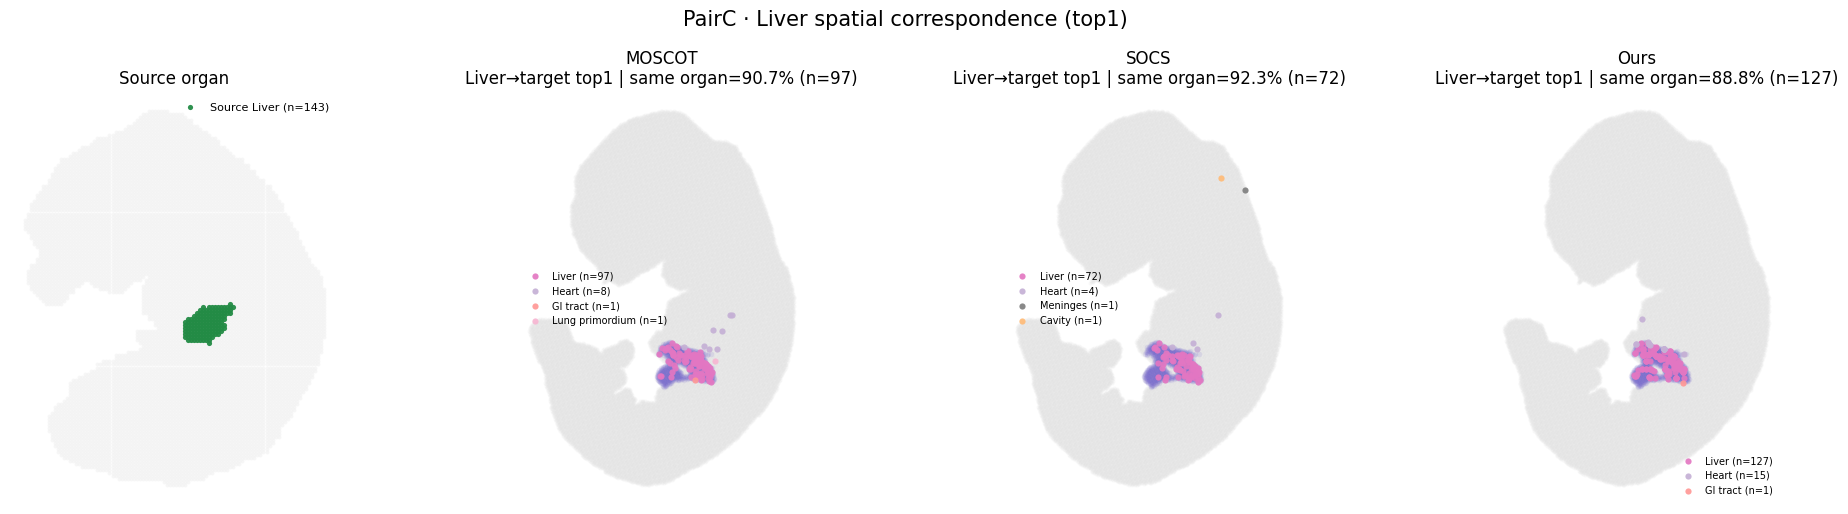


=== PairC | Lung primordium ===


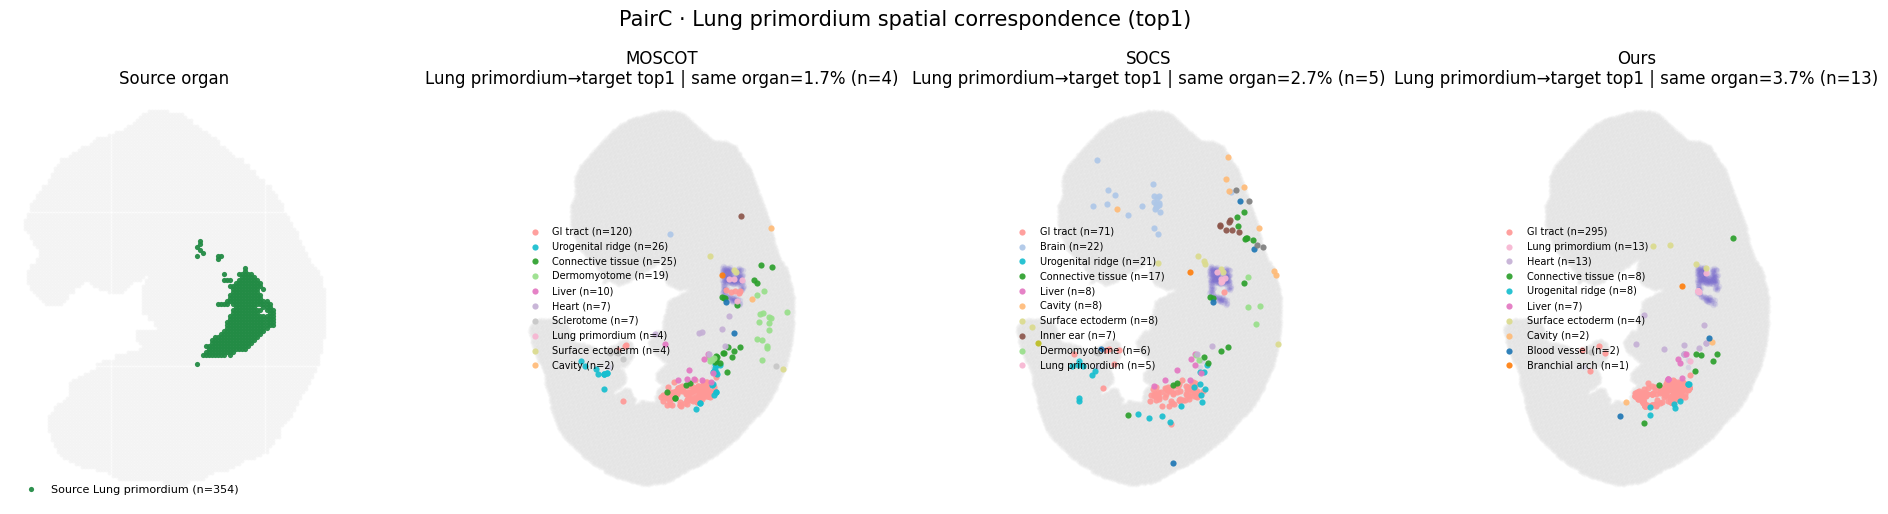


=== PairC | Mesenchyme ===


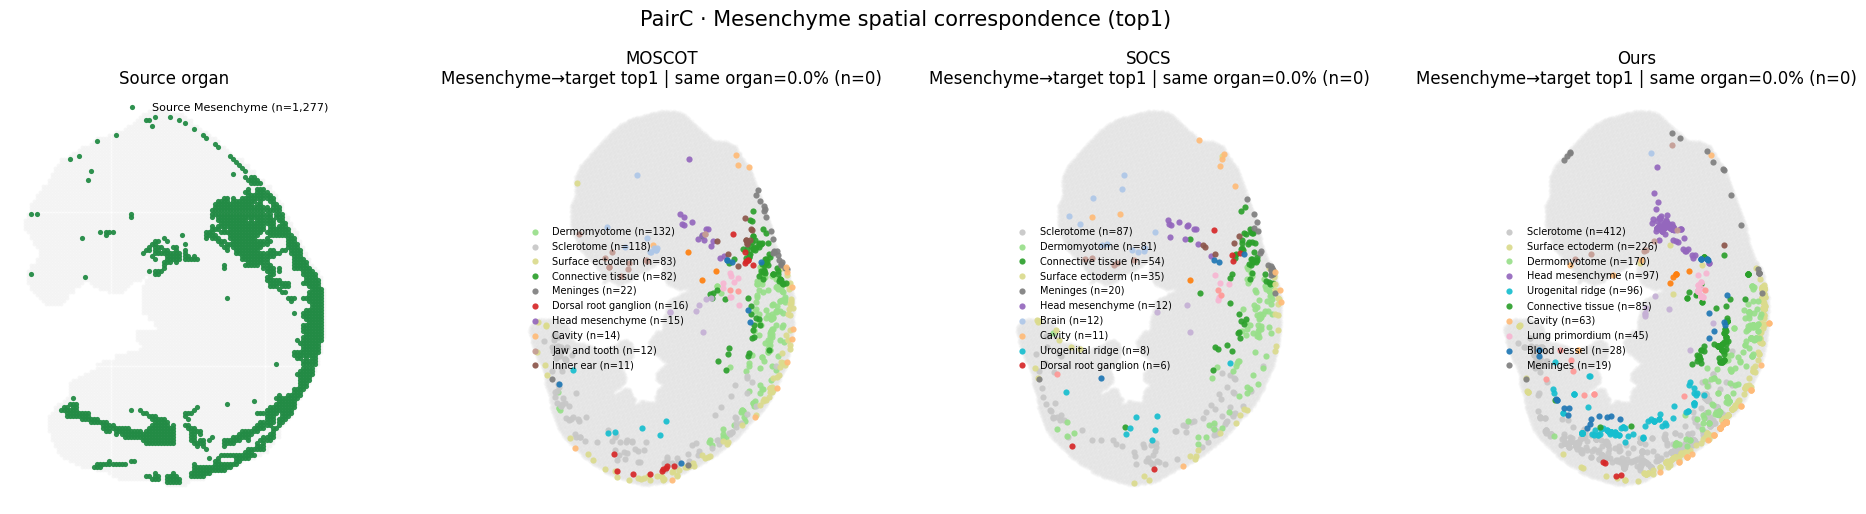


=== PairC | Mucosal epithelium ===


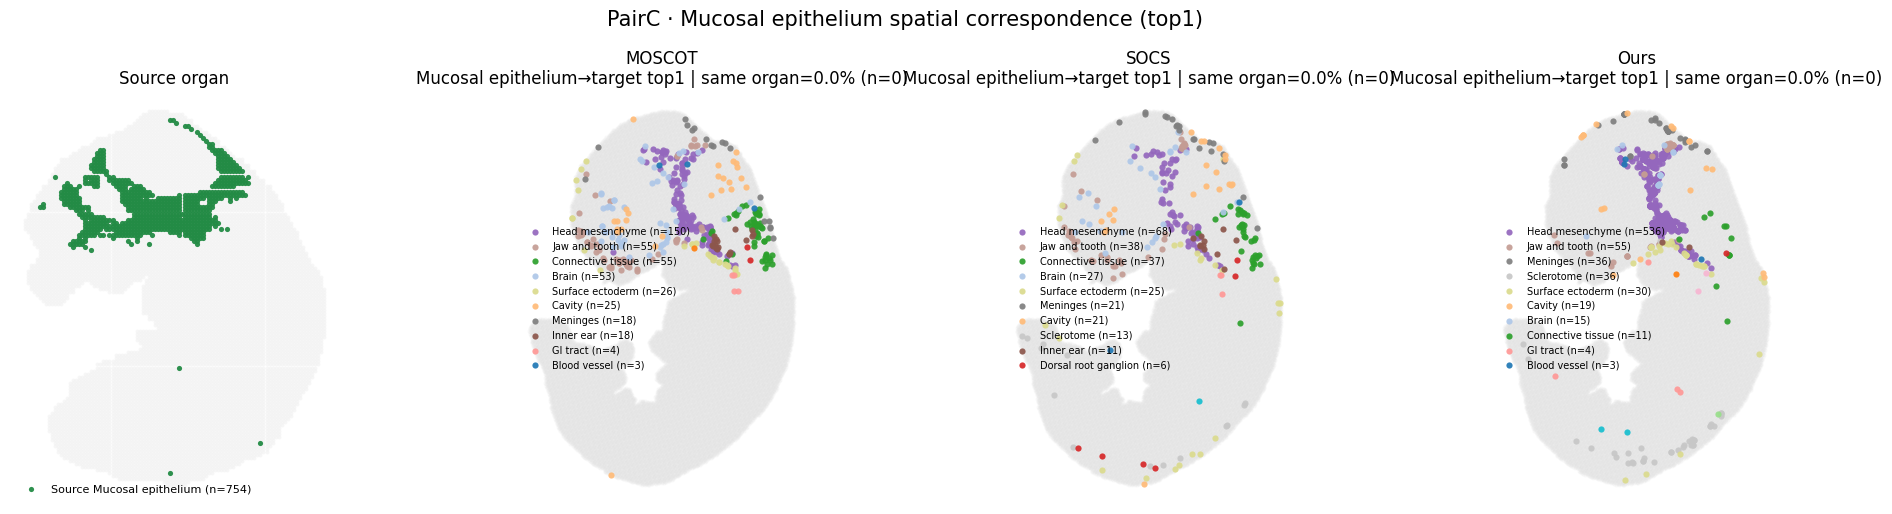


=== PairC | Notochord ===


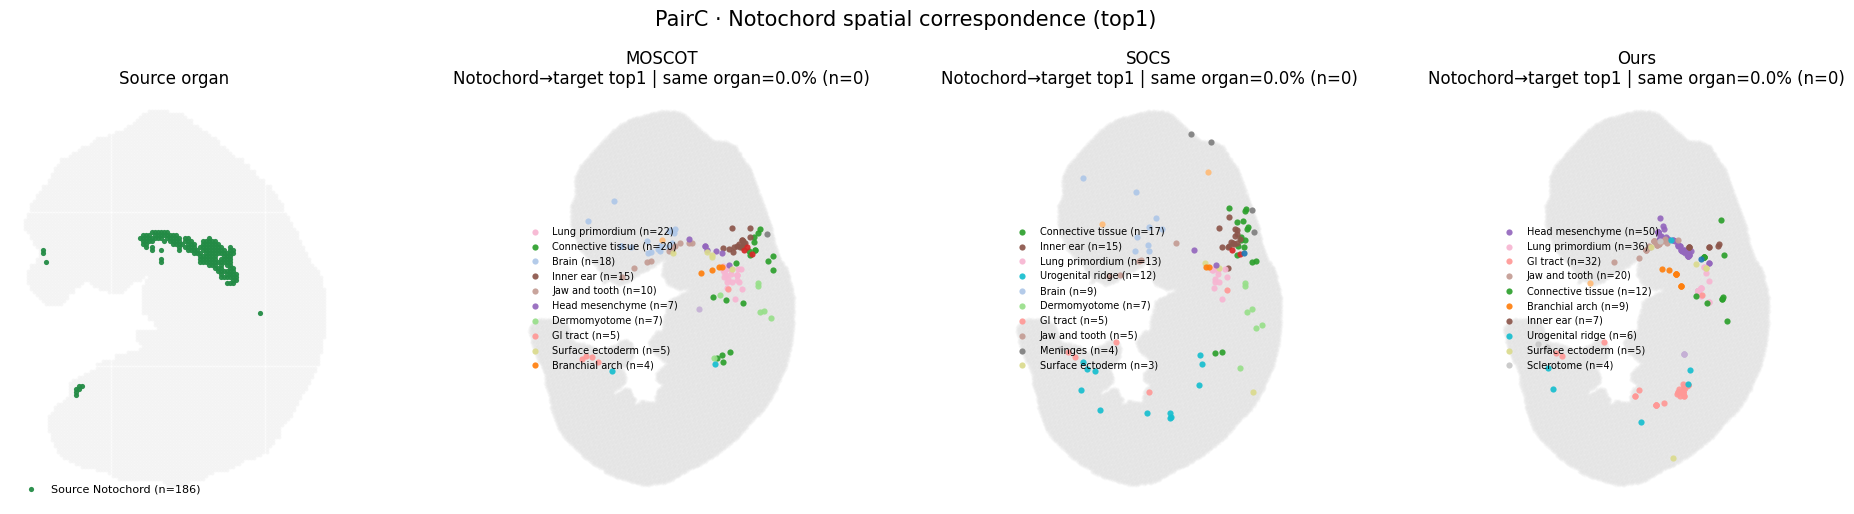


=== PairC | Sclerotome ===


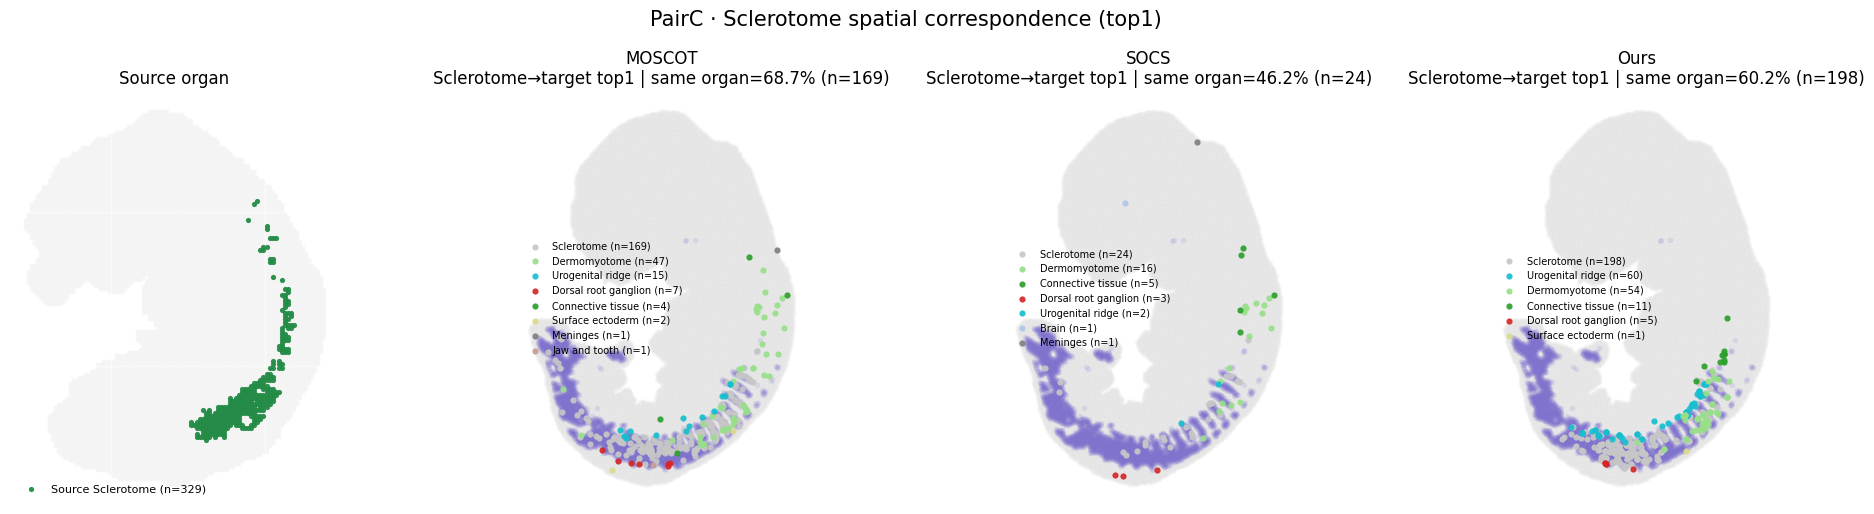


=== PairC | Spinal cord ===


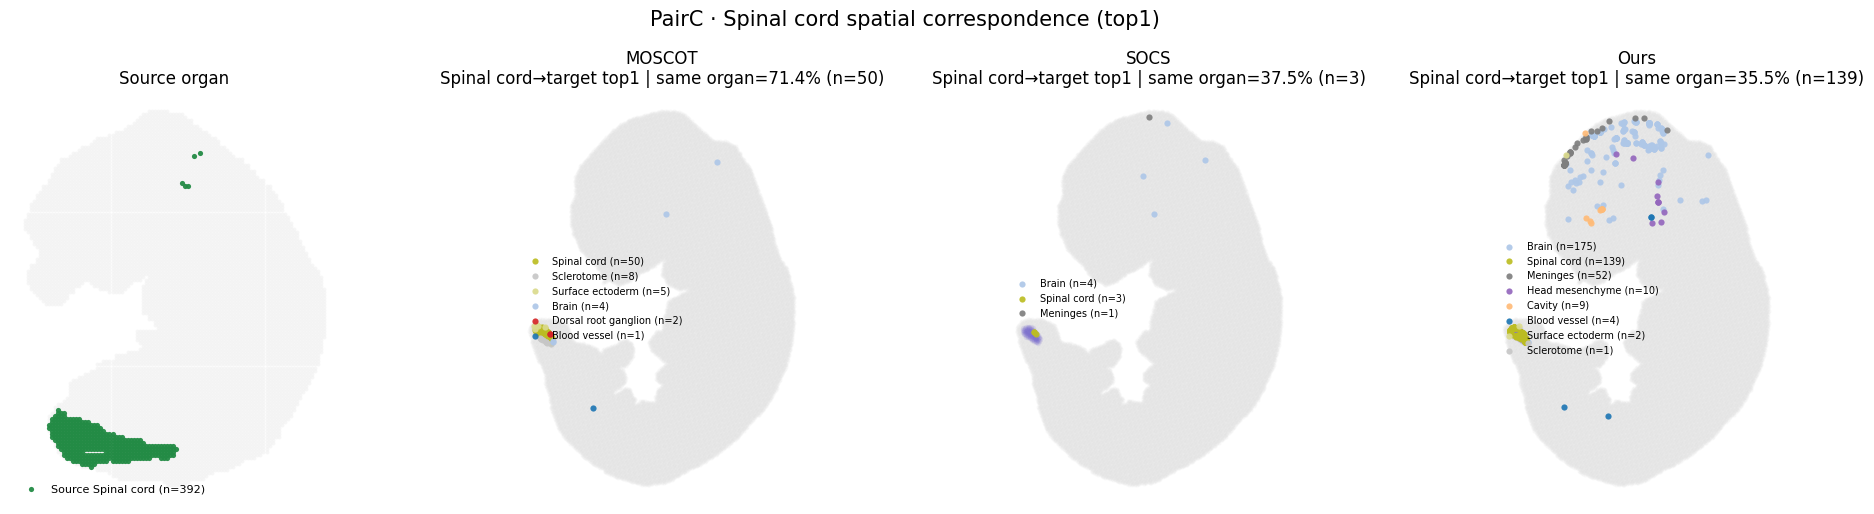


=== PairC | Urogenital ridge ===


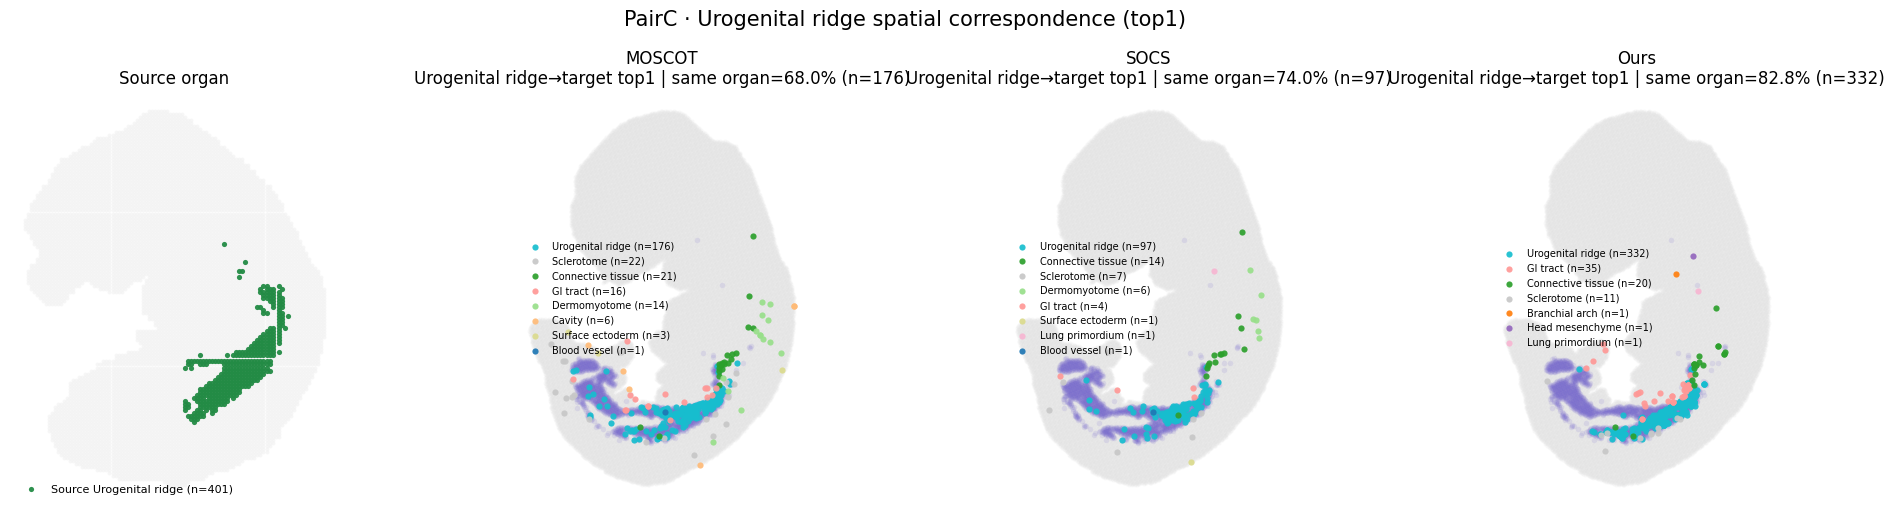

In [1]:
# ============================================================
# PairA & PairC
# Spatial correspondence screening for ALL source organs
#
# For each source organ:
#   [1] Source organ spatial map
#   [2] MOSCOT top1 target spots
#   [3] SOCS top1 target spots
#   [4] Ours top1 target spots
#
# Target top1 spots are colored by TARGET annotation.
# Optionally, the same-organ region on the target is shown
# as a light background highlight.
#
# No expression is used.
# No curated transition is used.
# No feasible set is recomputed.
# No figures are saved.
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import anndata as ad
import matplotlib.pyplot as plt

# ============================================================
# 0. CONFIG
# ============================================================

SHOW_SAME_ORGAN_BG = True   # show faint same-organ target region in background
MAX_LEGEND_ITEMS = 10       # keep legend readable
FIG_W = 20
FIG_H = 5.2

PAIR_CFG = {
    "PairA": {
        "source": Path("/mnt/disk2/lirui/domain_concentration_repro/input/PairA_source_E9.5_E1S1.h5ad"),
        "target": Path("/mnt/disk2/lirui/domain_concentration_repro/input/PairA_target_E10.5_E2S1.h5ad"),
        "moscot_root": Path(
            "/mnt/disk2/lirui/mosta_growth_marginal_ablation/no_growth_score/"
            "E9.5_E1S1__E10.5_E2S1/results/E9.5_E1S1__E10.5_E2S1/X_nbvae_30"
        ),
        "socs": Path("/mnt/disk2/lirui/mosta_socs_official_unsupervised/PairA/best_transport.npy"),
        "ours_sparse_dir": Path("/mnt/disk2/lirui/mosta_e105_e115_baselines/pareto/PairA/src1_tgt0p6/stage2"),
        "dense_has_name_files": True,
    },
    "PairC": {
        "source": Path("/mnt/disk2/lirui/mosta_e105_e115_nbvae30/data/E10.5_E2S1.nbvae30.h5ad"),
        "target": Path("/mnt/disk2/lirui/mosta_e105_e115_nbvae30/data/E11.5_E1S1.nbvae30.h5ad"),
        "moscot": Path("/mnt/disk2/lirui/mosta_e105_e115_baselines/moscot/best_weighted/transport.npy"),
        "socs": Path("/mnt/disk2/lirui/mosta_e105_e115_baselines/socs/PairC/best_transport.npy"),
        "ours_sparse": Path("/mnt/disk2/lirui/mosta_e105_e115_baselines/pareto/PairC/src1_tgt0p6/stage2/PairC_src1_tgt0p6_stage2_transport_sparse.npz"),
        "dense_has_name_files": False,   # assumes PairC dense transports align directly to h5ad
    },
}

# colors
C_BG = "#E2E2E2"
C_SRC = "#238B45"
C_SAME_ORGAN_BG = "#6A5ACD"

# ============================================================
# 1. HELPERS
# ============================================================

def make_palette(labels):
    base = (
        list(plt.get_cmap("tab20").colors)
        + list(plt.get_cmap("tab20b").colors)
        + list(plt.get_cmap("tab20c").colors)
    )
    uniq = sorted(pd.unique(labels))
    return {lab: base[i % len(base)] for i, lab in enumerate(uniq)}

def read_names(path):
    path = Path(path)
    if not path.exists():
        return None
    return np.atleast_1d(np.loadtxt(path, dtype=str)).astype(str)

def align_names(full_names, saved_names, adata):
    idx = pd.Index(full_names).get_indexer(saved_names)
    if np.any(idx < 0) and "original_obs_name" in adata.obs.columns:
        idx = pd.Index(
            adata.obs["original_obs_name"].astype(str).to_numpy()
        ).get_indexer(saved_names)

    if np.any(idx < 0):
        bad = saved_names[idx < 0][:10].tolist()
        raise KeyError(f"Cannot align saved names. Examples: {bad}")
    return idx.astype(np.int64)

def weighted_best_moscot_dir(root):
    rows = []
    for mp in sorted(root.glob("task_*/metrics.json")):
        m = json.loads(mp.read_text())
        if m.get("status") != "success":
            continue
        w = m.get("accuracy", m.get("weighted_accuracy"))
        if w is None:
            continue
        rows.append((float(w), int(m["task_id"]), mp.parent))
    if not rows:
        raise RuntimeError(f"No successful MOSCOT task found under:\n{root}")
    return max(rows, key=lambda x: (x[0], -x[1]))[2]

def load_dense_top1(
    transport_path,
    src_adata,
    tgt_adata,
    source_names_path=None,
    target_names_path=None,
):
    src_names = src_adata.obs_names.astype(str).to_numpy()
    tgt_names = tgt_adata.obs_names.astype(str).to_numpy()
    ns, nt = src_adata.n_obs, tgt_adata.n_obs

    P = np.load(transport_path, mmap_mode="r")

    saved_src = read_names(source_names_path) if source_names_path else None
    saved_tgt = read_names(target_names_path) if target_names_path else None

    src_idx = np.arange(ns) if saved_src is None else align_names(src_names, saved_src, src_adata)
    tgt_idx = np.arange(nt) if saved_tgt is None else align_names(tgt_names, saved_tgt, tgt_adata)

    if P.shape != (len(src_idx), len(tgt_idx)):
        raise ValueError(
            f"{transport_path}\n"
            f"transport shape = {P.shape}, expected = {(len(src_idx), len(tgt_idx))}"
        )

    top1 = np.full(ns, -1, dtype=np.int32)

    for lo in range(0, P.shape[0], 512):
        hi = min(lo + 512, P.shape[0])

        block = np.asarray(P[lo:hi], dtype=np.float32)
        row_mass = block.sum(axis=1)
        active = np.isfinite(row_mass) & (row_mass > 0)

        rows = src_idx[lo:hi][active]
        if len(rows) == 0:
            continue

        top1[rows] = tgt_idx[np.argmax(block[active], axis=1)]

    return top1

def load_sparse_top1(path, n_source):
    z = np.load(path)
    offsets = np.asarray(z["row_offsets"], dtype=np.int64)
    tgt_idx = np.asarray(z["target_indices"], dtype=np.int32)
    mass = np.asarray(z["mass"], dtype=np.float64)

    if len(offsets) != n_source + 1:
        raise ValueError(f"Sparse transport has {len(offsets)-1} rows, expected {n_source}")

    top1 = np.full(n_source, -1, dtype=np.int32)

    for i in range(n_source):
        lo, hi = offsets[i], offsets[i + 1]
        if hi <= lo:
            continue
        row = mass[lo:hi]
        if np.isfinite(row).all() and row.sum() > 0:
            top1[i] = tgt_idx[lo + np.argmax(row)]

    return top1

def clean_axis(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")
    for sp in ax.spines.values():
        sp.set_visible(False)

def draw_source_panel(ax, src_xy, src_mask, organ):
    ax.scatter(src_xy[:, 0], src_xy[:, 1], s=8, c=C_BG, alpha=0.28, linewidths=0, zorder=0)
    ax.scatter(
        src_xy[src_mask, 0],
        src_xy[src_mask, 1],
        s=14,
        c=C_SRC,
        alpha=0.95,
        linewidths=0,
        label=f"Source {organ} (n={src_mask.sum():,})",
        zorder=2,
    )
    ax.set_title("Source organ", fontsize=12)
    ax.legend(frameon=False, fontsize=8, loc="best")
    clean_axis(ax)
    ax.invert_yaxis()

def draw_target_panel(ax, tgt_xy, tgt_ann, top1, src_mask, organ, method, palette, add_bg_same_organ=True):
    active_src = np.flatnonzero(src_mask & (top1 >= 0))
    dest = top1[active_src]

    # background tissue
    ax.scatter(tgt_xy[:, 0], tgt_xy[:, 1], s=8, c=C_BG, alpha=0.22, linewidths=0, zorder=0)

    # optional background same-organ region
    if add_bg_same_organ:
        same = (tgt_ann == organ)
        if same.sum() > 0:
            ax.scatter(
                tgt_xy[same, 0],
                tgt_xy[same, 1],
                s=16,
                c=C_SAME_ORGAN_BG,
                alpha=0.12,
                linewidths=0,
                zorder=1,
            )

    if len(dest) == 0:
        ax.set_title(f"{method}\nno active top1", fontsize=12)
        clean_axis(ax)
        ax.invert_yaxis()
        return

    dest_ann = tgt_ann[dest]

    # draw top1 target spots by target organ
    counts = pd.Series(dest_ann).value_counts()
    ordered_labs = counts.index.tolist()

    for lab in ordered_labs:
        m = (dest_ann == lab)
        ax.scatter(
            tgt_xy[dest[m], 0],
            tgt_xy[dest[m], 1],
            s=20,
            c=[palette[lab]],
            alpha=0.92,
            linewidths=0,
            label=f"{lab} (n={m.sum():,})",
            zorder=2,
        )

    same_n = int((dest_ann == organ).sum())
    same_pct = 100 * same_n / len(dest) if len(dest) else np.nan

    ax.set_title(
        f"{method}\n{organ}→target top1 | same organ={same_pct:.1f}% (n={same_n:,})",
        fontsize=12
    )

    handles, labels = ax.get_legend_handles_labels()
    if len(labels) > MAX_LEGEND_ITEMS:
        handles = handles[:MAX_LEGEND_ITEMS]
        labels = labels[:MAX_LEGEND_ITEMS]
    ax.legend(handles, labels, frameon=False, fontsize=7, loc="best")

    clean_axis(ax)
    ax.invert_yaxis()

def load_pair(pair):
    cfg = PAIR_CFG[pair]

    src = ad.read_h5ad(cfg["source"])
    tgt = ad.read_h5ad(cfg["target"])

    src_ann = src.obs["annotation"].astype(str).to_numpy()
    tgt_ann = tgt.obs["annotation"].astype(str).to_numpy()
    src_xy = np.asarray(src.obsm["spatial"])[:, :2]
    tgt_xy = np.asarray(tgt.obsm["spatial"])[:, :2]
    ns = src.n_obs

    # MOSCOT
    if pair == "PairA":
        mdir = weighted_best_moscot_dir(cfg["moscot_root"])
        top1_m = load_dense_top1(
            mdir / "transport.npy",
            src, tgt,
            mdir / "source_obs_names.txt",
            mdir / "target_obs_names.txt",
        )
        top1_s = load_dense_top1(
            cfg["socs"],
            src, tgt,
            cfg["socs"].parent / "source_obs_names.txt",
            cfg["socs"].parent / "target_obs_names.txt",
        )
        ours_hits = list(cfg["ours_sparse_dir"].glob("*_transport_sparse.npz"))
        if len(ours_hits) != 1:
            raise RuntimeError(
                f"Expected one sparse transport under {cfg['ours_sparse_dir']}, found {ours_hits}"
            )
        top1_o = load_sparse_top1(ours_hits[0], ns)

    elif pair == "PairC":
        top1_m = load_dense_top1(cfg["moscot"], src, tgt)
        top1_s = load_dense_top1(cfg["socs"], src, tgt)
        top1_o = load_sparse_top1(cfg["ours_sparse"], ns)

    else:
        raise ValueError(pair)

    organs = sorted(pd.unique(src_ann))
    palette = make_palette(tgt_ann)

    return {
        "src": src,
        "tgt": tgt,
        "src_ann": src_ann,
        "tgt_ann": tgt_ann,
        "src_xy": src_xy,
        "tgt_xy": tgt_xy,
        "organs": organs,
        "palette": palette,
        "top1": {
            "MOSCOT": top1_m,
            "SOCS": top1_s,
            "Ours": top1_o,
        },
    }

def plot_one_organ(D, pair, organ):
    src_mask = (D["src_ann"] == organ)

    if src_mask.sum() == 0:
        print(f"[skip] {pair} | {organ}: source organ not found")
        return

    fig, axes = plt.subplots(1, 4, figsize=(FIG_W, FIG_H))

    draw_source_panel(
        axes[0],
        D["src_xy"],
        src_mask,
        organ,
    )

    for ax, method in zip(axes[1:], ["MOSCOT", "SOCS", "Ours"]):
        draw_target_panel(
            ax=ax,
            tgt_xy=D["tgt_xy"],
            tgt_ann=D["tgt_ann"],
            top1=D["top1"][method],
            src_mask=src_mask,
            organ=organ,
            method=method,
            palette=D["palette"],
            add_bg_same_organ=SHOW_SAME_ORGAN_BG,
        )

    fig.suptitle(f"{pair} · {organ} spatial correspondence (top1)", fontsize=15)
    plt.tight_layout()
    plt.show()

# ============================================================
# 2. LOAD BOTH PAIRS ONCE
# ============================================================

PAIR_DATA = {}
for pair in ["PairA", "PairC"]:
    print("=" * 90)
    print(f"Loading {pair}")
    print("=" * 90)
    PAIR_DATA[pair] = load_pair(pair)
    print(f"{pair}: {len(PAIR_DATA[pair]['organs'])} source organs")
    print(PAIR_DATA[pair]["organs"])

# ============================================================
# 3. PLOT ALL ORGANS
# ============================================================

for pair in ["PairA", "PairC"]:
    D = PAIR_DATA[pair]
    print("\n" + "#" * 110)
    print(f"{pair}: plotting all {len(D['organs'])} source organs")
    print("#" * 110)

    for organ in D["organs"]:
        print(f"\n=== {pair} | {organ} ===")
        plot_one_organ(D, pair, organ)